# Mobilidade urbana e mercado imobiliário no Rio de Janeiro (2011–2024)

**Ana Alice Silva · Mayara A. P. Bomback · Henrique Lara**  
FGV EMAp — Análise Exploratória de Dados e Visualização, 2026.2

*Rascunho para a entrega intermediária. Os resultados poderão ser revisados até a entrega final.*

## Resumo

Investigamos a associação entre proximidade ao transporte público e preços por m² de transações residenciais no Rio de Janeiro (2011–2024). Esta entrega parcial descreve a proximidade ao Metrô, BRT e VLT e compara medianas de preços para Metrô e BRT, com limiar de 500 m e filtros de área e preço. No Metrô, a diferença entre as medianas gerais é de 83,39%, e a mediana das diferenças por bairro, ano e tipologia é de 1,73%. No BRT, as medidas ficam próximas de zero. Os resultados são descritivos e cobrem apenas parte das perguntas; a análise completa incluirá as quatro modalidades, inclusive o BRS.


## 1. Introdução

A infraestrutura de transporte público amplia as possibilidades de deslocamento e constitui uma característica relevante da localização dos imóveis. Investigar sua associação com os preços ajuda a compreender diferenças espaciais do mercado imobiliário. Essa relação também depende do bairro, do período e das características dos imóveis, exigindo cuidado na comparação de transações próximas e distantes.

O projeto examina transações residenciais no Rio de Janeiro entre 2011 e 2024 e sua relação com Metrô, BRT, VLT e BRS. Nesta etapa, a comparação geral do Metrô apresenta uma diferença de preços maior que a comparação dentro de grupos de bairro, ano e tipologia; no BRT, ambas as medidas estão próximas de zero. Essas estatísticas descrevem conjuntos distintos e não identificam efeito causal.

O artigo apresenta os dados, a integração espacial e as oito perguntas da proposta. Os espaços de contribuição dos colegas e as análises previstas para a próxima entrega estão identificados.


## 2. Dados imobiliários — ITBI

### 2.1. Unificação e tratamento dos dados

Foram utilizadas duas bases de transações imobiliárias do ITBI, disponibilizadas pela Prefeitura do Rio de Janeiro, abrangendo os períodos de 2011–2018 e 2019–2024. As bases foram unificadas, preservando o ano, os valores e as características individuais de cada transação.

Na limpeza, foram corrigidos problemas de codificação e padronizados os campos de endereço e tipologia. Selecionaram-se apenas transações classificadas como residenciais, referentes a casas e apartamentos. Transações com endereços incompletos foram identificadas e preservadas em uma base auxiliar, mas não submetidas à geocodificação, devido à insuficiência de informações para sua localização.

### 2.2. Geocodificação dos imóveis

Para obter as coordenadas geográficas, utilizou-se a biblioteca *geocodebr*, baseada no Cadastro Nacional de Endereços para Fins Estatísticos (CNEFE/IBGE). Endereços idênticos foram agrupados antes da geocodificação, evitando consultas repetidas sem eliminar transações imobiliárias.

Os resultados foram classificados conforme sua precisão. Para as análises espaciais, priorizaram-se coordenadas localizadas pelo número ou número aproximado do imóvel, com desvio estimado de até 30 metros e localização geograficamente plausível no município.

### 2.3. Tratamento de valores inconsistentes e extremos

O valor por metro quadrado (`valor_m2`) foi recalculado dividindo-se o valor da transação pela área registrada. Transações sem preço ou área válidos foram excluídas das bases analíticas, por impossibilitarem esse cálculo.

Para identificar possíveis valores atípicos, aplicou-se, separadamente para cada ano, um critério de três intervalos interquartis (IQR) sobre o logaritmo do preço por m². Os registros extremos foram sinalizados e mantidos em uma versão separada, permitindo análises com e sem esses valores.

Esses procedimentos buscam reduzir distorções nas análises de preços e distâncias, embora não garantam a ausência de erros nos registros originais. A seleção por precisão geográfica e a exclusão de valores extremos também podem alterar a representatividade da amostra.

## 3. Dados de mobilidade


### 3.1. Preparação espacial

As camadas de Metrô, BRT e VLT do Data.Rio representam pontos de embarque; o BRS é representado por corredores e foi tratado separadamente. Em `02_mobilidade.ipynb`, foram examinadas as geometrias e as informações de início de operação, com projeção para **EPSG:31983**, que permite calcular distâncias em metros.

### 3.2. Complementação dos anos de operação

A base geográfica do **VLT não informava datas de inauguração**. O grupo acrescentou anos de início de operação a partir das fontes históricas listadas nas referências. São informações adicionadas pelo grupo, não datas completas do dataset; **Itamaraty permaneceu sem ano identificado**, e as atribuições individuais ainda requerem validação. No BRS, datas inconsistentes em Centro-Tijuca e Passos não foram substituídas por anos presumidos.


## 4. Integração e metodologia

### 4.1. Distâncias e disponibilidade histórica

O CSV integrado associa cada transação residencial geocodificada ao ano, bairro, tipologia, área, preço por m² e distâncias em linha reta às estações de Metrô, BRT e VLT consideradas disponíveis naquele ano. O procedimento está em `03_integracao_itbi.ipynb`. A base ainda não contém distância ao BRS; seu critério de acesso será definido na próxima entrega, distinguindo corredor de ponto de embarque.

Transações a **até 500 m** são classificadas como próximas; acima desse limiar, como distantes. Distâncias ausentes ou inválidas são excluídas da classificação. O uso de anos de operação não distingue o mês de inauguração.

O código e as instruções de reprodução estão no [repositório do projeto](https://github.com/ana-alice17/mobilidade-imobiliario-rj).


### 4.2. Recorte de preços

Selecionamos área finita **≥ 25 m²** e **0 < preço por m² ≤ R$ 100.000**, obtendo **315.284 transações**. O filtro reduz a influência de áreas pequenas e valores extremos, sem certificar a validade de cada registro. A saída de carregamento informa a retenção em relação à base integrada.


### 4.3. Contexto espacial

A figura apresenta a proporção anual de transações a até 500 m do Metrô, BRT e VLT, usando como denominador as transações com distância válida para cada modalidade e ano. Utiliza a base integrada antes do filtro de preços; não representa a parcela de residências da cidade atendida pelo transporte. O BRS ainda não está incluído.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ=Path.cwd().resolve()
if RAIZ.name=="notebooks":
    RAIZ=RAIZ.parent
"""Cálculos descritivos compartilhados pelos notebooks 03 e 05."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODAIS = {"Metrô": "dist_metro_m", "BRT": "dist_brt_m", "VLT": "dist_vlt_m"}
CHAVES = ["nm_bairro_norm", "ano", "ds_imovel_tipologia"]

def preparar(dados):
    dados = dados.copy()
    obrigatorias = set(CHAVES + ["area", "valor_m2", *MODAIS.values()])
    if obrigatorias - set(dados):
        raise ValueError(f"Colunas ausentes: {sorted(obrigatorias - set(dados))}")
    for col in ["area", "valor_m2", "ano", *MODAIS.values()]:
        dados[col] = pd.to_numeric(dados[col], errors="coerce")
    if "id_transacao" in dados and (dados.id_transacao.isna().any() or not dados.id_transacao.is_unique):
        raise ValueError("Identificadores de transação ausentes ou duplicados.")
    amostra = dados.loc[np.isfinite(dados.area) & dados.area.ge(25)
                        & dados.valor_m2.gt(0) & dados.valor_m2.le(100_000)].copy()
    return dados, amostra

def distancia_valida(df, col):
    return np.isfinite(df[col]) & df[col].ge(0)

def comparar(amostra, limite=500, minimo=10):
    resultados, detalhes = [], {}
    for modal in ["Metrô", "BRT"]:
        col = MODAIS[modal]
        base = amostra.loc[distancia_valida(amostra,col)].copy()
        base["perto"] = base[col].le(limite)
        completa = base.dropna(subset=CHAVES)
        for chave in ["nm_bairro_norm", "ds_imovel_tipologia"]:
            completa = completa.loc[completa[chave].astype(str).str.strip().ne("")]
        agregado = completa.groupby(CHAVES + ["perto"]).valor_m2.agg(n="size", mediana="median")
        n = agregado.n.unstack("perto").reindex(columns=[False,True],fill_value=0).fillna(0)
        med = agregado.mediana.unstack("perto").reindex(columns=[False,True])
        g = pd.DataFrame({"n_longe":n[False], "n_perto":n[True],
                          "mediana_longe":med[False], "mediana_perto":med[True]})
        g = g.loc[g.n_longe.ge(minimo)&g.n_perto.ge(minimo)].copy()
        g["diferenca_pct"] = 100*(g.mediana_perto/g.mediana_longe-1)
        detalhes[modal] = g
        geral = base.groupby("perto").valor_m2.median().reindex([False,True])
        incluidos = int(g[["n_longe","n_perto"]].to_numpy().sum())
        resultados.append(dict(modalidade=modal,n_amostra=len(amostra),n_distancia_valida=len(base),
            n_chaves_completas=len(completa),grupos_avaliados=len(n),grupos_comparaveis=len(g),
            cobertura_grupos_pct=100*len(g)/len(n) if len(n) else np.nan,
            n_transacoes_comparaveis=incluidos,
            cobertura_amostra_pct=100*incluidos/len(amostra) if len(amostra) else np.nan,
            cobertura_distancia_valida_pct=100*incluidos/len(base) if len(base) else np.nan,
            mediana_geral_longe=geral[False],mediana_geral_perto=geral[True],
            diferenca_geral_pct=100*(geral[True]/geral[False]-1),
            mediana_diferencas_grupos_pct=g.diferenca_pct.median()))
    return pd.DataFrame(resultados), detalhes

def tabela_artigo(resumo):
    tabela = resumo.set_index("modalidade")[["diferenca_geral_pct","mediana_diferencas_grupos_pct",
        "grupos_comparaveis","n_transacoes_comparaveis","cobertura_amostra_pct"]].rename(columns={
        "diferenca_geral_pct":"Diferença geral (%)", "mediana_diferencas_grupos_pct":"Diferença por grupo¹ (%)",
        "grupos_comparaveis":"Grupos", "n_transacoes_comparaveis":"Transações", "cobertura_amostra_pct":"Cobertura² (%)"})
    tabela.index.name="Modalidade"
    return tabela.round(2)

def evolucao_proximidade(dados):
    proporcao = pd.DataFrame(index=sorted(dados.ano.dropna().unique()))
    denominadores = pd.DataFrame(index=proporcao.index)
    for modal,col in MODAIS.items():
        validas = dados.loc[distancia_valida(dados,col)]
        denominadores[modal] = validas.groupby("ano").size().reindex(proporcao.index,fill_value=0)
        proporcao[modal] = validas[col].le(500).groupby(validas.ano).mean()*100
    proporcao.index.name=denominadores.index.name="Ano"
    return proporcao,denominadores

def figura_proximidade(proporcao):
    fig,ax=plt.subplots(figsize=(8,3.4))
    proporcao.plot(ax=ax,marker="o",markersize=3)
    ax.set(xlabel="Ano",ylabel="Transações com distância válida (%)",
           title="Transações a até 500 m — Metrô, BRT e VLT")
    ax.grid(axis="y",alpha=.2)
    fig.tight_layout()
    return fig

def figura_comparacao(resumo):
    fig,eixos=plt.subplots(1,2,figsize=(9,3.5))
    tabela=resumo.set_index("modalidade")
    tabela[["diferenca_geral_pct","mediana_diferencas_grupos_pct"]].rename(columns={
        "diferenca_geral_pct":"Geral", "mediana_diferencas_grupos_pct":"Por grupo¹"}).plot.bar(ax=eixos[0],rot=0)
    eixos[0].set(title="Diferenças entre medianas",ylabel="Diferença (%)",xlabel="")
    eixos[0].axhline(0,color="black",linewidth=.7)
    tabela[["cobertura_amostra_pct","cobertura_grupos_pct"]].rename(columns={
        "cobertura_amostra_pct":"Transações²", "cobertura_grupos_pct":"Grupos³"}).plot.bar(ax=eixos[1],rot=0)
    eixos[1].set(title="Cobertura da comparação",ylabel="Cobertura (%)",xlabel="",ylim=(0,100))
    for ax in eixos:
        ax.grid(axis="y",alpha=.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


# Use a saída atual da integração ou sua cópia compactada.
ARQUIVO=RAIZ/"data/processed/itbi_com_distancias.csv"
if not ARQUIVO.is_file():
    ARQUIVO=RAIZ/"data/processed/itbi_com_distancias.csv.gz"
if not ARQUIVO.is_file():
    raise FileNotFoundError("Base ausente. Consulte as instruções do README.")
dados,amostra=preparar(pd.read_csv(ARQUIVO,low_memory=False))

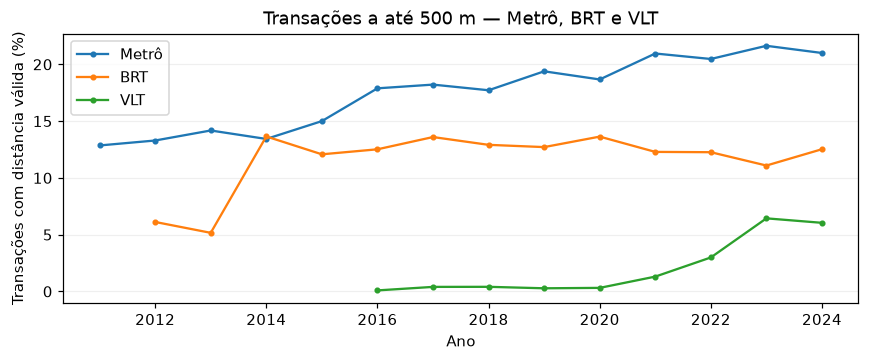

In [2]:
evolucao,cobertura_anual=evolucao_proximidade(dados)
figura_proximidade(evolucao)
plt.show()


Mudanças nas proporções podem refletir a infraestrutura cadastrada, a disponibilidade das distâncias e a concentração de transações em poucos endereços. A figura contextualiza a integração; não responde à pergunta 8 sobre a evolução dos preços.


## 5. Perguntas e resultados


### 5.1. Como os valores dos imóveis negociados pelo ITBI se distribuem no município do Rio de Janeiro?

**Base das seções 5.1 a 5.4.** As quatro primeiras perguntas descrevem o preço do m² antes de qualquer cruzamento com transporte, então usam a base residencial completa (`itbi_residencial_2011_2024_geocodificado_completo.csv.gz`), e não apenas as transações com distância calculada. Excluímos somente os **1.514 registros (0,3%) sinalizados como extremos** pelo critério da seção 2.3, restando **440.155 transações** de julho de 2011 a dezembro de 2024. Não aplicamos outro corte: a seção 5.3 mostra quanto cada medida muda com e sem os valores das pontas.

Diferentemente da seção 5.5, os valores destas seções estão **corrigidos pelo IPCA para reais de dezembro de 2024** (variável `m2_real`). No período, o IPCA acumulou cerca de 114%, e juntar anos sem correção misturaria inflação com diferença de preço. O índice de cada mês é estimado por interpolação geométrica da variação anual do IPCA: índice(a, m) = índice<sub>dez</sub>(a − 1) × (1 + IPCA<sub>a</sub>)<sup>m/12</sup>. Para a seção 5.4, cada bairro foi associado à sua Área de Planejamento (AP) da Prefeitura por um dicionário montado a partir da divisão administrativa do IPP, já que a base não traz essa informação. A análise exploratória completa está em `04_analise_imobiliaria.ipynb`.

**Procedimento.** O código faz dois histogramas do m² corrigido: um em escala linear, com o eixo cortado no percentil 99,5, e outro em escala logarítmica, com todas as transações. Calcula também a assimetria (`skew()`) do preço e do seu logaritmo e os percentis 5, 25, 50, 75 e 95. A distribuição no espaço é mostrada num mapa de hexágonos (`hexbin`) com as transações de geocodificação de alta precisão (`lat_analise`, `lon_analise`). Cada hexágono, com cerca de 600 m de largura e pelo menos 10 transações, recebe a **mediana** do m². Como o mapa depende de coordenadas, o código antes mede a cobertura da geocodificação em cada AP.

In [ ]:
# Seções 5.1–5.4: base residencial completa, valores em R$ de dez/2024
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D

itbi_bruto = pd.read_csv(RAIZ / "data/processed/itbi_residencial_2011_2024_geocodificado_completo.csv.gz",
                         low_memory=False)
if itbi_bruto.valor_m2_suspeito.dtype != bool:
    itbi_bruto["valor_m2_suspeito"] = itbi_bruto.valor_m2_suspeito.astype(str).str.strip().str.lower().eq("true")
itbi = itbi_bruto.loc[~itbi_bruto.valor_m2_suspeito].copy()

# IPCA, variação acumulada no ano (%) — IBGE
IPCA = {2011: 6.50, 2012: 5.84, 2013: 5.91, 2014: 6.41, 2015: 10.67, 2016: 6.29, 2017: 2.95,
        2018: 3.75, 2019: 4.31, 2020: 4.52, 2021: 10.06, 2022: 5.79, 2023: 4.62, 2024: 4.83}
INDICE_DEZ = {2010: 1.0}
for a in range(2011, 2025):
    INDICE_DEZ[a] = INDICE_DEZ[a - 1] * (1 + IPCA[a] / 100)

def corrigir_ipca(base):
    # índice(a, m) = índice_dez(a − 1) × (1 + IPCA_a)^(m/12); resultado em R$ de dez/2024
    indice = np.array([INDICE_DEZ[a - 1] * (1 + IPCA[a] / 100) ** (m / 12) for a, m in zip(base.ano, base.mes)])
    return base.valor_m2 * INDICE_DEZ[2024] / indice

itbi["m2_real"] = corrigir_ipca(itbi)

AREAS_PLANEJAMENTO = {
    'AP1 · Centro': [
        'SAUDE', 'GAMBOA', 'SANTO CRISTO', 'CAJU', 'CENTRO', 'CATUMBI',
        'RIO COMPRIDO', 'CIDADE NOVA', 'ESTACIO', 'IMPERIAL DE SAO CRISTOVAO', 'MANGUEIRA', 'BENFICA',
        'VASCO DA GAMA', 'PAQUETA', 'SANTA TERESA'],
    'AP2 · Zona Sul e Tijuca': [
        'FLAMENGO', 'GLORIA', 'LARANJEIRAS', 'CATETE', 'COSME VELHO', 'BOTAFOGO',
        'HUMAITA', 'URCA', 'LEME', 'COPACABANA', 'IPANEMA', 'LEBLON',
        'LAGOA', 'JARDIM BOTANICO', 'GAVEA', 'VIDIGAL', 'SAO CONRADO', 'ROCINHA',
        'PRACA DA BANDEIRA', 'TIJUCA', 'ALTO DA BOA VISTA', 'MARACANA', 'VILA ISABEL', 'ANDARAI',
        'GRAJAU'],
    'AP3 · Zona Norte': [
        'RAMOS', 'BONSUCESSO', 'OLARIA', 'MANGUINHOS', 'PENHA', 'PENHA CIRCULAR',
        'BRAZ DE PINA', 'CORDOVIL', 'PARADA DE LUCAS', 'VIGARIO GERAL', 'JARDIM AMERICA', 'HIGIENOPOLIS',
        'JACARE', 'MARIA DA GRACA', 'DEL CASTILHO', 'INHAUMA', 'ENGENHO DA RAINHA', 'TOMAS COELHO',
        'JACAREZINHO', 'SAO FRANCISCO XAVIER', 'ROCHA', 'RIACHUELO', 'SAMPAIO', 'ENGENHO NOVO',
        'LINS DE VASCONCELOS', 'MEIER', 'TODOS OS SANTOS', 'CACHAMBI', 'ENGENHO DE DENTRO', 'AGUA SANTA',
        'ENCANTADO', 'PIEDADE', 'ABOLICAO', 'PILARES', 'VILA KOSMOS', 'VICENTE DE CARVALHO',
        'VILA DA PENHA', 'VISTA ALEGRE', 'IRAJA', 'COLEGIO', 'CAMPINHO', 'QUINTINO BOCAIUVA',
        'CAVALCANTI', 'ENGENHEIRO LEAL', 'CASCADURA', 'MADUREIRA', 'VAZ LOBO', 'TURIACU',
        'ROCHA MIRANDA', 'HONORIO GURGEL', 'OSWALDO CRUZ', 'BENTO RIBEIRO', 'MARECHAL HERMES', 'GUADALUPE',
        'ANCHIETA', 'PARQUE ANCHIETA', 'RICARDO DE ALBUQUERQUE', 'COELHO NETO', 'ACARI', 'BARROS FILHO',
        'COSTA BARROS', 'PAVUNA', 'PARQUE COLUMBIA', 'RIBEIRA', 'ZUMBI', 'CACUIA',
        'PITANGUEIRAS', 'PRAIA DA BANDEIRA', 'COCOTA', 'BANCARIOS', 'FREGUESIA ILHA', 'JARDIM GUANABARA',
        'JARDIM CARIOCA', 'TAUA', 'MONERO', 'PORTUGUESA', 'GALEAO', 'CIDADE UNIVERSITARIA',
        'COMPLEXO DO ALEMAO', 'MARE'],
    'AP4 · Barra e Jacarepaguá': [
        'JACAREPAGUA', 'ANIL', 'GARDENIA AZUL', 'CIDADE DE DEUS', 'CURICICA', 'FREGUESIA JACAREPAGUA',
        'PECHINCHA', 'TAQUARA', 'TANQUE', 'PRACA SECA', 'VILA VALQUEIRE', 'JOA',
        'ITANHANGA', 'BARRA DA TIJUCA', 'CAMORIM', 'VARGEM PEQUENA', 'VARGEM GRANDE', 'RECREIO DOS BANDEIRANTES',
        'GRUMARI'],
    'AP5 · Zona Oeste': [
        'DEODORO', 'VILA MILITAR', 'CAMPO DOS AFONSOS', 'JARDIM SULACAP', 'MAGALHAES BASTOS', 'REALENGO',
        'PADRE MIGUEL', 'BANGU', 'SENADOR CAMARA', 'GERICINO', 'SANTISSIMO', 'CAMPO GRANDE',
        'SENADOR VASCONCELOS', 'INHOAIBA', 'COSMOS', 'PACIENCIA', 'SANTA CRUZ', 'SEPETIBA',
        'GUARATIBA', 'BARRA DE GUARATIBA', 'PEDRA DE GUARATIBA'],
}

BAIRRO_AP = {b: ap for ap, bairros in AREAS_PLANEJAMENTO.items() for b in bairros}
ORDEM_AP = list(AREAS_PLANEJAMENTO)
itbi["ap"] = pd.Categorical(itbi.nm_bairro_norm.map(BAIRRO_AP), categories=ORDEM_AP, ordered=True)

# Apresentação: estilo local (não altera as figuras das outras seções) e números no padrão brasileiro
AZUL, LARANJA, CINZA, TINTA = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
ESTILO_H = {"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10.5,
            "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.alpha": 0.25,
            "legend.frameon": False, "text.parse_math": False}

def reais(v):
    return "R$ " + f"{v:,.0f}".replace(",", ".")

def nome_bairro(b):
    return " ".join(p if p in {"de", "da", "do", "dos", "das", "e"} else p.capitalize() for p in str(b).lower().split())

def fmt_tabela(d, formatos):
    # Exibe a tabela com milhar em ponto e decimal em vírgula; formatos = {coluna: "{:,.0f}"}
    troca = str.maketrans({",": ".", ".": ","})
    out = pd.DataFrame(index=d.index)
    for col in d.columns:
        out[col] = [formatos.get(col, "{:,.0f}").format(v).translate(troca) if pd.notna(v) else "" for v in d[col]]
    return out

fmt_milhar = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
fmt_reais = mticker.FuncFormatter(lambda v, _: reais(v))

print(f"Base residencial: {len(itbi_bruto):,} transações · extremos excluídos: {itbi_bruto.valor_m2_suspeito.sum():,} · "
      f"base das seções 5.1–5.4: {len(itbi):,}".replace(",", "."))
print("Bairros sem AP:", list(itbi.loc[itbi.ap.isna() & itbi.nm_bairro_norm.notna(), "nm_bairro_norm"].unique()) or "nenhum")

Base residencial: 441.669 transações · extremos excluídos: 1.514 · base das seções 5.1–5.4: 440.155
Bairros sem AP: nenhum


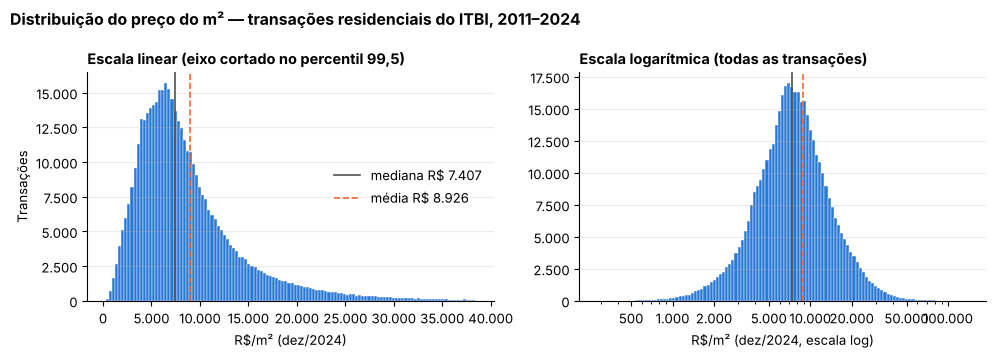

Assimetria: 2,97 (escala linear) · -0,13 (escala log)
Percentis: P5 R$ 2.595 · P25 R$ 5.055 · P50 R$ 7.407 · P75 R$ 10.845 · P95 R$ 20.422


,transações,mediana,% do total
Tipo de imóvel,,,
APARTAMENTO,375.571,7.935,"85,3"
CASA,62.075,4.454,"14,1"
PROLETÁRIO (casa/apto),2.509,3.741,"0,6"


In [ ]:
x = itbi.m2_real
media, mediana, corte = x.mean(), x.median(), x.quantile(0.995)

with plt.rc_context(ESTILO_H):
    fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6))
    eixos[0].hist(x[x <= corte], bins=120, color=AZUL, edgecolor="white", linewidth=0.3)
    eixos[0].set(title="Escala linear (eixo cortado no percentil 99,5)", xlabel="R$/m² (dez/2024)", ylabel="Transações")
    eixos[1].hist(x, bins=np.logspace(np.log10(x.min()), np.log10(x.max()), 120), color=AZUL, edgecolor="white", linewidth=0.3)
    eixos[1].set_xscale("log")
    eixos[1].set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000, 100000])
    eixos[1].set(title="Escala logarítmica (todas as transações)", xlabel="R$/m² (dez/2024, escala log)")
    for ax in eixos:
        ax.axvline(mediana, color=TINTA, lw=1.2)
        ax.axvline(media, color=LARANJA, lw=1.2, ls="--")
        ax.xaxis.set_major_formatter(fmt_milhar)
        ax.yaxis.set_major_formatter(fmt_milhar)
        ax.grid(axis="x", visible=False)
    eixos[0].legend(handles=[Line2D([], [], color=TINTA, lw=1.2, label=f"mediana {reais(mediana)}"),
                             Line2D([], [], color=LARANJA, lw=1.2, ls="--", label=f"média {reais(media)}")],
                    loc="center right")
    fig.suptitle("Distribuição do preço do m² — transações residenciais do ITBI, 2011–2024", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()

print(f"Assimetria: {x.skew():.2f} (escala linear) · {np.log(x).skew():.2f} (escala log)".replace(".", ","))
print("Percentis:", " · ".join(f"P{int(q * 100)} {reais(x.quantile(q))}" for q in [.05, .25, .5, .75, .95]))
tipo = itbi.ds_imovel_tipologia.where(itbi.ds_imovel_tipologia.isin(["APARTAMENTO", "CASA"]), "PROLETÁRIO (casa/apto)")
display(fmt_tabela(itbi.groupby(tipo).m2_real.agg(transações="size", mediana="median")
                   .assign(**{"% do total": lambda t: 100 * t["transações"] / t["transações"].sum()}),
                   {"% do total": "{:.1f}"}).rename_axis("Tipo de imóvel"))

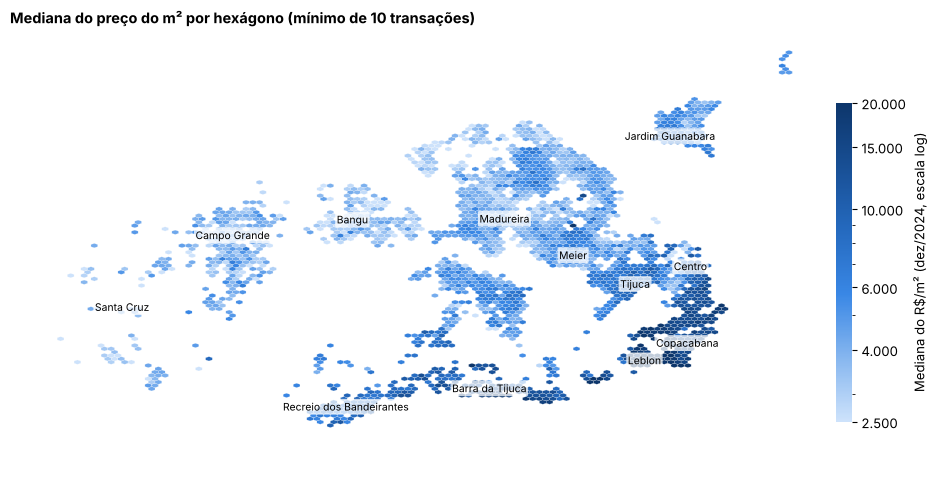

Transações no mapa: 318.709 de 440.155 (72%)


,% com coordenada de alta precisão
Área de Planejamento,
AP1 · Centro,"81,5"
AP2 · Zona Sul e Tijuca,"90,0"
AP3 · Zona Norte,"84,2"
AP4 · Barra e Jacarepaguá,"53,3"
AP5 · Zona Oeste,"58,7"


In [ ]:
geo = itbi.dropna(subset=["lat_analise", "lon_analise"])
cobertura = itbi.groupby("ap", observed=True).lat_analise.apply(lambda s: 100 * s.notna().mean())

with plt.rc_context(ESTILO_H):
    fig, ax = plt.subplots(figsize=(10, 5.6))
    hb = ax.hexbin(geo.lon_analise, geo.lat_analise, C=geo.m2_real, reduce_C_function=np.median,
                   gridsize=110, mincnt=10, cmap=AZUIS, norm=LogNorm(vmin=2500, vmax=20000),
                   linewidths=0.15, edgecolors="white")
    ax.set_aspect(1 / np.cos(np.deg2rad(-22.92)))
    ax.set_axis_off()
    cb = fig.colorbar(hb, ax=ax, shrink=0.6, pad=0.01)
    cb.set_label("Mediana do R$/m² (dez/2024, escala log)")
    cb.set_ticks([2500, 4000, 6000, 10000, 15000, 20000])
    cb.ax.yaxis.set_major_formatter(fmt_milhar)
    cb.ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    cb.outline.set_visible(False)
    posicao = geo.groupby("nm_bairro_norm")[["lon_analise", "lat_analise"]].median()
    for b in ["LEBLON", "COPACABANA", "CENTRO", "TIJUCA", "MEIER", "MADUREIRA", "BARRA DA TIJUCA",
              "RECREIO DOS BANDEIRANTES", "CAMPO GRANDE", "SANTA CRUZ", "BANGU", "JARDIM GUANABARA"]:
        if b in posicao.index:
            ax.annotate(nome_bairro(b), tuple(posicao.loc[b]), fontsize=7.5, ha="center", va="center",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
    ax.set_title("Mediana do preço do m² por hexágono (mínimo de 10 transações)")
    fig.tight_layout()
    plt.show()

print(f"Transações no mapa: {len(geo):,} de {len(itbi):,} ({len(geo) / len(itbi):.0%})".replace(",", "."))
display(fmt_tabela(cobertura.to_frame("% com coordenada de alta precisão"),
                   {"% com coordenada de alta precisão": "{:.1f}"}).rename_axis("Área de Planejamento"))

**Interpretação.** A distribuição do preço do m² é **fortemente assimétrica à direita** (assimetria de 2,97). A maior parte das transações está numa faixa relativamente estreita, e uma cauda longa ultrapassa R$ 100 mil/m². Metade das vendas fica entre **R$ 5.055 e R$ 10.845 por m²**, e 90% entre R$ 2.595 e R$ 20.422. Na escala logarítmica a assimetria praticamente desaparece (−0,13). O preço do m² se comporta aproximadamente como uma variável log-normal, o que justifica usar escala log para comparar grupos. Apartamentos são 85% das transações, com m² mediano de R$ 7.935, contra R$ 4.454 nas casas, que são 14%.

No espaço, há um gradiente claro. Os valores mais altos estão na orla da Zona Sul (Leblon, Ipanema, Lagoa) e numa faixa da Barra da Tijuca. Centro, Tijuca, Méier e Recreio ficam numa posição intermediária, e os preços caem em direção ao norte e ao oeste (Bangu, Campo Grande, Santa Cruz). O mapa deve ser lido com cuidado: a geocodificação de alta precisão cobre 90% das transações da AP2, mas só 53% da AP4 e 59% da AP5. Por isso, as comparações entre regiões da seção 5.4 usam todas as transações, pelo bairro declarado.

### 5.2. Qual é o valor médio e mediano do m² dos imóveis analisados e qual é a diferença entre essas medidas?

**Procedimento.** O código calcula a média (`mean()`) e a mediana (`median()`) do m² com os valores corrigidos e com os nominais, além da diferença e da razão entre as duas medidas. Para verificar se a diferença depende de poucos casos ou de anos específicos, calcula a fração de transações abaixo da média e repete a razão média/mediana para cada ano.

In [ ]:
def medidas_centrais(s):
    return pd.Series({"Transações": len(s), "Média": s.mean(), "Mediana": s.median(),
                      "Média − mediana": s.mean() - s.median(), "Média / mediana": s.mean() / s.median()})

centrais = pd.DataFrame({"Corrigido (R$ de dez/2024)": medidas_centrais(itbi.m2_real),
                         "Nominal": medidas_centrais(itbi.valor_m2)}).T
display(fmt_tabela(centrais, {"Média": "R$ {:,.0f}", "Mediana": "R$ {:,.0f}", "Média − mediana": "R$ {:,.0f}",
                              "Média / mediana": "{:.2f}"}).rename_axis("Valores do m²"))

razao_ano = itbi.groupby("ano").m2_real.agg(lambda s: s.mean() / s.median())
print(f"Transações com m² abaixo da média: {(itbi.m2_real < itbi.m2_real.mean()).mean():.0%}")
print(f"Razão média/mediana por ano: de {razao_ano.min():.2f} ({razao_ano.idxmin()}) a {razao_ano.max():.2f} ({razao_ano.idxmax()})".replace(".", ","))

,Transações,Média,Mediana,Média − mediana,Média / mediana
Valores do m²,,,,,
Corrigido (R$ de dez/2024),440.155,R$ 8.926,R$ 7.407,R$ 1.519,"1,21"
Nominal,440.155,R$ 6.230,R$ 5.200,R$ 1.030,"1,20"


Transações com m² abaixo da média: 63%
Razão média/mediana por ano: de 1,15 (2018) a 1,28 (2012)


**Interpretação.** Em reais de dezembro de 2024, o **m² médio é R$ 8.926 e o mediano, R$ 7.407**. A média fica R$ 1.519 acima da mediana, **21% a mais**. Em valores nominais as medidas seriam R$ 6.230 e R$ 5.200: eles subestimam o preço atual por misturar reais de anos diferentes, mas a relação entre média e mediana é praticamente a mesma (1,20).

A diferença decorre da assimetria vista na seção 5.1. A mediana divide as transações ao meio e não depende do tamanho dos valores da cauda, enquanto a média é puxada para cima pelos poucos imóveis de R$ 30, 50 ou 100 mil/m². Ela não se deve a casos isolados: aparece em todos os anos, com a média entre 15% e 28% acima da mediana. Como a média corresponde a um m² mais caro que o de 63% das transações, **a mediana é a medida adequada do m² típico** e é a usada nas comparações seguintes.

### 5.3. Qual é a dispersão dos valores do m², considerando variância, desvio padrão e amplitude?

**Procedimento.** Uma função calcula as três medidas pedidas, **variância** (`var()`), **desvio padrão** (`std()`) e **amplitude** (máximo − mínimo), e duas complementares: o **intervalo interquartil** (IIQ = Q3 − Q1), largura da faixa dos 50% centrais, que não depende dos extremos, e o **coeficiente de variação** (CV = desvio padrão / média). Para medir o peso dos valores das pontas, a função é aplicada a três versões da base: a completa, com os extremos da seção 2.3 também corrigidos pela inflação; a base de análise; e a base de análise sem o 1% mais baixo e o 1% mais alto. O código lista ainda as cinco menores e as cinco maiores transações da base de análise.

In [ ]:
def dispersao(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"Transações": len(s), "Variância (R$²)": s.var(), "Desvio padrão": s.std(),
                      "Mínimo": s.min(), "Máximo": s.max(), "Amplitude": s.max() - s.min(),
                      "IIQ (Q3 − Q1)": q3 - q1, "CV": s.std() / s.mean(), "Mediana": s.median()})

p01, p99 = itbi.m2_real.quantile([.01, .99])
versoes = pd.DataFrame({
    "Base completa (com extremos)": dispersao(corrigir_ipca(itbi_bruto)),
    "Base de análise": dispersao(itbi.m2_real),
    "Base de análise sem 1% das pontas": dispersao(itbi.m2_real[itbi.m2_real.between(p01, p99)]),
})
display(fmt_tabela(versoes.T, {"CV": "{:.2f}"}).T.rename_axis("Medida (R$/m² de dez/2024)"))
display(Markdown(f"Versão aparada: transações entre o percentil 1 ({reais(p01)}) e o percentil 99 ({reais(p99)}) da base de análise."))

colunas = ["ano", "nm_bairro_norm", "ds_imovel_tipologia", "area", "valor_transacoes", "m2_real"]
print("Cinco menores e cinco maiores m² da base de análise:")
print(pd.concat([itbi.nsmallest(5, "m2_real"), itbi.nlargest(5, "m2_real")])[colunas].round(0).to_string(index=False))

,Base completa (com extremos),Base de análise,Base de análise sem 1% das pontas
Medida (R$/m² de dez/2024),,,
Transações,441.669,440.155,431.351
Variância (R$²),28.766.189.671,39.301.484,26.538.091
Desvio padrão,169.606,6.269,5.152
Mínimo,0,287,1.480
Máximo,92.484.000,138.150,32.169
Amplitude,92.484.000,137.863,30.689
IIQ (Q3 − Q1),5.802,5.790,5.642
CV,"17,94","0,70","0,59"
Mediana,7.392,7.407,7.407


Versão aparada: transações entre o percentil 1 (R$ 1.480) e o percentil 99 (R$ 32.169) da base de análise.

Cinco menores e cinco maiores m² da base de análise:
 ano nm_bairro_norm  ds_imovel_tipologia  area  valor_transacoes  m2_real
2024     COPACABANA          APARTAMENTO  38.0           10851.0    287.0
2024     COPACABANA          APARTAMENTO  39.0           11227.0    291.0
2024     COPACABANA          APARTAMENTO  49.0           14319.0    295.0
2024     COPACABANA          APARTAMENTO  34.0            9962.0    299.0
2024    LARANJEIRAS                 CASA 139.0           41470.0    300.0
2013         LEBLON                 CASA 380.0        27145064.0 138150.0
2012        IPANEMA          APARTAMENTO 508.0        28000000.0 113918.0
2012        IPANEMA          APARTAMENTO 311.0        17000000.0 111384.0
2013 VARGEM PEQUENA PROLETARIO CASA/APTO  52.0         3000000.0 111041.0
2014        IPANEMA          APARTAMENTO  83.0         5134000.0 110461.0


**Interpretação.** Na base de análise, a **variância é de 39,3 milhões de R$²**, o **desvio padrão é R$ 6.269** e a **amplitude é R$ 137.863** (de R$ 287 a R$ 138.150 por m²). O coeficiente de variação é 0,70: o desvio padrão equivale a 70% da média. As três medidas reagem de forma muito diferente aos valores das pontas.

A **amplitude** depende de apenas duas transações e é a menos informativa. Com os extremos chega a R$ 92 milhões/m², sem eles cai para R$ 137.863, e sem o 1% de cada ponta, para R$ 30.689. Os valores que sobram nas pontas também são duvidosos: o mínimo vem de apartamentos em Copacabana declarados por cerca de R$ 10 mil, e entre os maiores está um imóvel proletário de 52 m² em Vargem Pequena declarado por R$ 3 milhões. A **variância** e o **desvio padrão** usam todas as transações, mas elevam os desvios ao quadrado. Os 1.514 extremos, 0,3% da base, multiplicam o desvio padrão por 27, e retirar mais 1% de cada ponta ainda o reduz em 18%, para R$ 5.152. A variância, expressa em reais ao quadrado, é de difícil leitura; o desvio padrão reporta a mesma informação na escala original. Já o **IIQ** quase não muda entre as três versões (R$ 5.802, R$ 5.790 e R$ 5.642), e a mediana fica em R$ 7.407 nas duas versões filtradas.

A dispersão do m² no Rio é, portanto, grande e não se explica por erros de registro: mesmo dentro dos 50% centrais, o m² do terceiro quartil (R$ 10.845) é o dobro do m² do primeiro (R$ 5.055). A seção 5.4 mostra que boa parte dessa dispersão está associada à localização.

### 5.4. Os valores do m² apresentam distribuição semelhante entre diferentes bairros ou regiões da cidade?

**Procedimento.** A comparação foi feita em dois níveis. Para as cinco Áreas de Planejamento, o código calcula mediana, média, quartis, IIQ relativo à mediana, CV e proporção de casas, e desenha um histograma por AP no mesmo eixo logarítmico para comparar posição e forma. Como a proporção de casas muda muito entre as regiões, repete a mediana considerando só apartamentos (`pivot_table` por AP e tipo). Para os bairros, considera apenas os que têm **pelo menos 200 transações** no período, cerca de 14 por ano, para que a mediana de cada um seja estável, e mostra os 15 mais caros e os 15 mais baratos com o intervalo Q1–Q3.

Para resumir o quanto os grupos diferem, o código calcula o **η² (eta ao quadrado)** do logaritmo do preço. O η² é a fração da variação total que corresponde a diferenças entre as médias dos grupos, e não à variação dentro deles: vale 0 se todos os grupos têm a mesma média e 1 se cada imóvel vale exatamente a média do seu grupo. O logaritmo é usado porque nessa escala a distribuição é quase simétrica e uma diferença de 2 vezes pesa igual em qualquer faixa de preço.

,Transações,Mediana,Média,Q1,Q3,IIQ / mediana,CV,% casas,Mediana / cidade,Mediana aptos
Área de Planejamento,,,,,,,,,,
AP1 · Centro,23.251,8.114,8.210,5.565,10.067,"0,55","0,52",8%,"1,10",8.348
AP2 · Zona Sul e Tijuca,119.263,12.161,14.014,8.532,17.463,"0,73","0,60",4%,"1,64",12.314
AP3 · Zona Norte,103.501,5.495,5.672,3.785,7.183,"0,62","0,47",22%,"0,74",5.856
AP4 · Barra e Jacarepaguá,157.315,7.685,8.397,5.849,10.164,"0,56","0,47",12%,"1,04",7.919
AP5 · Zona Oeste,36.733,4.067,4.308,3.083,5.160,"0,51","0,62",45%,"0,55",4.262


R$/m² de dez/2024. “% casas” inclui casas e imóveis proletários. “Mediana / cidade”: mediana da AP dividida pela mediana da cidade. “Mediana aptos”: só apartamentos.

Assimetria do log(R$/m²) por AP: AP1 -0,85 · AP2 -0,30 · AP3 -0,67 · AP4 -0,39 · AP5 -0,41


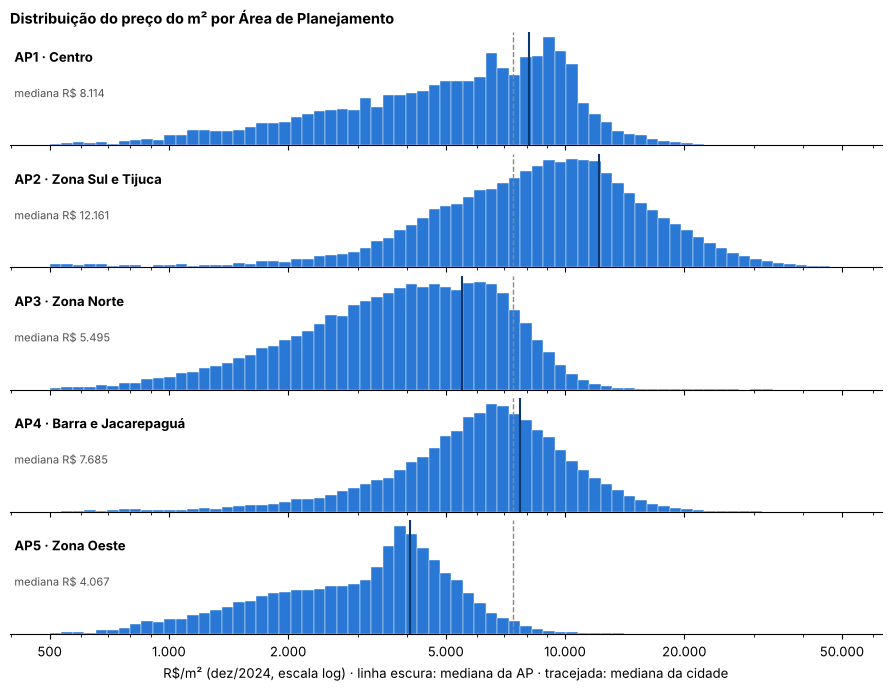

In [ ]:
def resumo_grupo(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"Transações": len(s), "Mediana": s.median(), "Média": s.mean(), "Q1": q1, "Q3": q3,
                      "IIQ / mediana": (q3 - q1) / s.median(), "CV": s.std() / s.mean()})

por_ap = itbi.groupby("ap", observed=True).m2_real.apply(resumo_grupo).unstack()
por_ap["% casas"] = itbi.groupby("ap", observed=True).ds_imovel_tipologia.apply(lambda s: 100 * (s != "APARTAMENTO").mean())
por_ap["Mediana / cidade"] = por_ap["Mediana"] / itbi.m2_real.median()
por_ap["Mediana aptos"] = (itbi[itbi.ds_imovel_tipologia == "APARTAMENTO"]
                           .groupby("ap", observed=True).m2_real.median())
display(fmt_tabela(por_ap, {"IIQ / mediana": "{:.2f}", "CV": "{:.2f}", "% casas": "{:.0f}%",
                            "Mediana / cidade": "{:.2f}"}).rename_axis("Área de Planejamento"))
display(Markdown("R$/m² de dez/2024. “% casas” inclui casas e imóveis proletários. “Mediana / cidade”: mediana da AP dividida pela mediana da cidade. “Mediana aptos”: só apartamentos."))

assimetria_log = itbi.groupby("ap", observed=True).m2_real.apply(lambda s: np.log(s).skew())
print("Assimetria do log(R$/m²) por AP:", " · ".join(f"{a.split(' ·')[0]} {v:.2f}" for a, v in assimetria_log.items()).replace(".", ","))

with plt.rc_context(ESTILO_H):
    fig, eixos = plt.subplots(len(ORDEM_AP), 1, figsize=(9, 7), sharex=True)
    bins = np.logspace(np.log10(500), np.log10(50000), 70)
    for ax, a in zip(eixos, ORDEM_AP):
        v = itbi.loc[itbi.ap == a, "m2_real"]
        ax.hist(v, bins=bins, density=True, color=AZUL, edgecolor="white", linewidth=0.3)
        ax.axvline(v.median(), color="#0d366b", lw=1.5)
        ax.axvline(itbi.m2_real.median(), color=CINZA, lw=1, ls="--")
        ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
        ax.text(0.005, 0.85, a, transform=ax.transAxes, fontweight="bold", va="top")
        ax.text(0.005, 0.52, f"mediana {reais(v.median())}", transform=ax.transAxes, fontsize=8, color=TINTA, va="top")
    eixos[-1].set_xscale("log")
    eixos[-1].set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000])
    eixos[-1].xaxis.set_major_formatter(fmt_milhar)
    eixos[-1].set_xlabel("R$/m² (dez/2024, escala log) · linha escura: mediana da AP · tracejada: mediana da cidade")
    eixos[0].set_title("Distribuição do preço do m² por Área de Planejamento")
    fig.tight_layout(h_pad=0.3)
    plt.show()

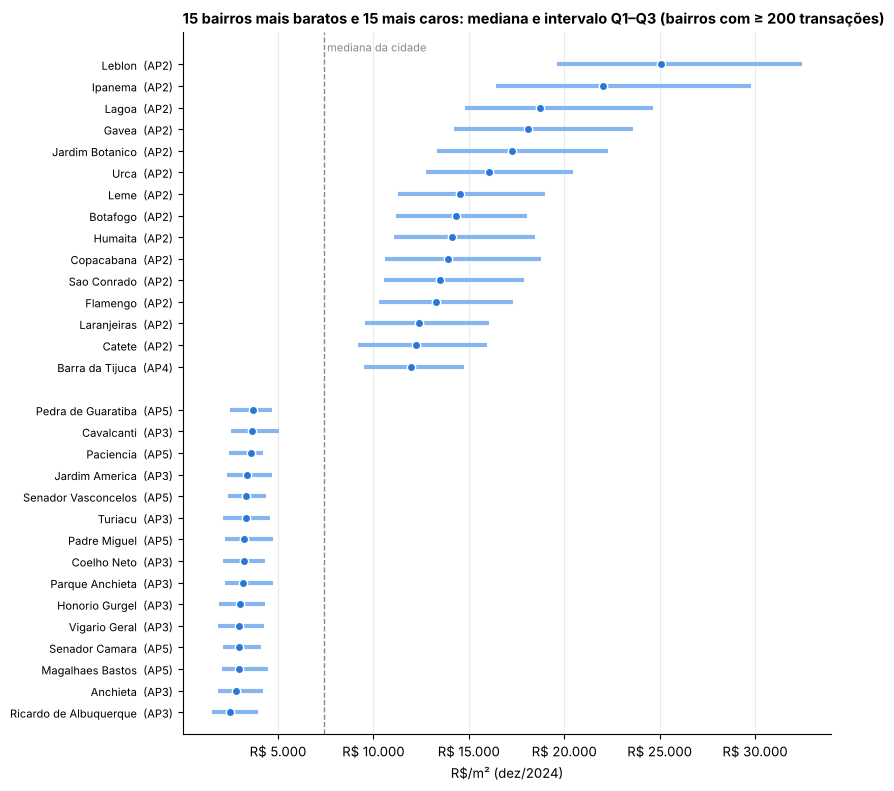

Bairros com transações: 156 · com pelo menos 200: 135 (99,6% das transações)
Mais caro: Leblon (R$ 25.079) · mais barato: Ricardo de Albuquerque (R$ 2.501) · razão 10,0×


In [ ]:
N_MIN = 200
por_bairro = (itbi.dropna(subset=["nm_bairro_norm"]).groupby("nm_bairro_norm")
              .agg(transações=("m2_real", "size"), mediana=("m2_real", "median"),
                   Q1=("m2_real", lambda s: s.quantile(.25)), Q3=("m2_real", lambda s: s.quantile(.75)),
                   ap=("ap", "first")))
elegiveis = por_bairro[por_bairro.transações >= N_MIN].sort_values("mediana")
extremos = pd.concat([elegiveis.head(15), elegiveis.tail(15)])

with plt.rc_context(ESTILO_H):
    fig, ax = plt.subplots(figsize=(8.5, 8))
    y = np.arange(len(extremos))
    y = np.where(y >= 15, y + 1, y)
    ax.hlines(y, extremos.Q1, extremos.Q3, color="#86b6ef", lw=3)
    ax.plot(extremos.mediana, y, "o", color=AZUL, ms=6, mec="white", mew=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{nome_bairro(b)}  ({a.split(' ·')[0]})" for b, a in zip(extremos.index, extremos.ap)], fontsize=8)
    ax.axvline(itbi.m2_real.median(), color=CINZA, lw=1, ls="--")
    ax.text(itbi.m2_real.median(), len(extremos) + 0.6, " mediana da cidade", fontsize=8, color=CINZA)
    ax.xaxis.set_major_formatter(fmt_reais)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-1, len(extremos) + 1.5)
    ax.set(xlabel="R$/m² (dez/2024)",
           title=f"15 bairros mais baratos e 15 mais caros: mediana e intervalo Q1–Q3 (bairros com ≥ {N_MIN} transações)")
    fig.tight_layout()
    plt.show()

print(f"Bairros com transações: {len(por_bairro)} · com pelo menos {N_MIN}: {len(elegiveis)} "
      f"({elegiveis.transações.sum() / len(itbi):.1%} das transações)".replace(".", ","))
razao = f"{elegiveis.mediana.iloc[-1] / elegiveis.mediana.iloc[0]:.1f}".replace(".", ",")
print(f"Mais caro: {nome_bairro(elegiveis.index[-1])} ({reais(elegiveis.mediana.iloc[-1])}) · "
      f"mais barato: {nome_bairro(elegiveis.index[0])} ({reais(elegiveis.mediana.iloc[0])}) · razão {razao}×")

In [ ]:
def eta2(valores, grupos):
    d = pd.DataFrame({"v": valores, "g": grupos}).dropna()
    media_grupo = d.groupby("g", observed=True).v.transform("mean")
    return ((media_grupo - d.v.mean()) ** 2).sum() / ((d.v - d.v.mean()) ** 2).sum()

log_m2 = np.log(itbi.m2_real)
eta = pd.Series({"Bairro (156 grupos)": eta2(log_m2, itbi.nm_bairro_norm),
                 "Área de Planejamento (5 grupos)": eta2(log_m2, itbi.ap),
                 "Tipo de imóvel": eta2(log_m2, itbi.ds_imovel_tipologia),
                 "Ano da transação (14 grupos)": eta2(log_m2, itbi.ano)}, name="η² sobre log(R$/m²)")
display(fmt_tabela((100 * eta).to_frame(), {"η² sobre log(R$/m²)": "{:.1f}%"}).rename_axis("Agrupamento"))

,η² sobre log(R$/m²)
Agrupamento,
Bairro (156 grupos),"55,6%"
Área de Planejamento (5 grupos),"34,4%"
Tipo de imóvel,"12,2%"
Ano da transação (14 grupos),"5,0%"


**Interpretação.** **Não: as distribuições são bem diferentes entre regiões e, mais ainda, entre bairros.** A AP2 (Zona Sul e Tijuca) tem m² mediano de **R$ 12.161**, 64% acima da mediana da cidade. A AP5 (Zona Oeste) tem **R$ 4.067**, 45% abaixo, e a diferença entre as duas é de **3 vezes**. AP1 (Centro) e AP4 (Barra e Jacarepaguá) ficam próximas da mediana da cidade (R$ 8.114 e R$ 7.685), e a AP3 (Zona Norte) fica abaixo (R$ 5.495). Os intervalos Q1–Q3 da AP2 e da AP5 nem se tocam: o primeiro quartil da AP2 (R$ 8.532) está acima do terceiro da AP5 (R$ 5.160).

As formas também diferem. A AP2 é a mais espalhada (IIQ de 0,73 vez a mediana), porque reúne do Leblon ao Andaraí. A AP5 tem um núcleo estreito em torno de R$ 4 mil (IIQ de 0,51 vez a mediana) e cauda longa para baixo. A AP1 tem a maior cauda de valores baixos (assimetria de −0,85 na escala log, contra −0,30 a −0,67 nas demais) e é a única em que média e mediana são praticamente iguais. A diferença **não se explica pela composição** de tipos de imóvel: a AP5 tem 45% de casas nas transações e a AP2, 4%, mas comparando só apartamentos a razão continua de 2,9 vezes (R$ 12.314 contra R$ 4.262).

Entre os 135 bairros com pelo menos 200 transações (99,6% da base), o m² mediano vai de R$ 2.501 em Ricardo de Albuquerque a R$ 25.079 no Leblon, **10 vezes mais**. Dos 15 bairros mais caros, 14 são da AP2, e o único de fora é a Barra da Tijuca. Os 15 mais baratos são todos da AP3 e da AP5. O **bairro explica 56% da variação do log do preço** e a AP, 34%, contra 12% do tipo de imóvel e 5% do ano da transação. Como as estações de Metrô se concentram na AP2, comparações de preço entre transações próximas e distantes do transporte que não controlem a localização tendem a refletir sobretudo essa diferença entre bairros, o que é coerente com a discrepância entre as comparações geral e por grupo da seção 5.5.

### 5.5. Qual é o valor médio e mediano do m² para imóveis localizados próximos e distantes dos pontos de acesso de Metrô, BRT, VLT e BRS?

**Resultado parcial — medianas de Metrô e BRT.** Usamos o recorte da seção 4.2 e o limiar de 500 m. Na comparação geral, calculamos 100 × (mediana perto / mediana longe − 1). Repetimos esse cálculo dentro de cada grupo de **bairro, ano e tipologia** com chaves completas e **pelo menos 10 transações perto e 10 longe**, resumindo as diferenças pela mediana, com peso igual por grupo.

A tabela apresenta as diferenças e a cobertura das transações; o gráfico mostra também a proporção de grupos elegíveis. As médias e as comparações de VLT e BRS serão completadas na próxima entrega.


In [3]:
resumo,grupos_por_modal=comparar(amostra)
display(tabela_artigo(resumo))
display(Markdown("¹ Mediana das diferenças percentuais dos grupos. ² Transações dos grupos / amostra de preços."))


,Diferença geral (%),Diferença por grupo¹ (%),Grupos,Transações,Cobertura² (%)
Modalidade,,,,,
Metrô,83.39,1.73,291,107385,34.06
BRT,-0.41,0.35,304,71832,22.78


¹ Mediana das diferenças percentuais dos grupos. ² Transações dos grupos / amostra de preços.

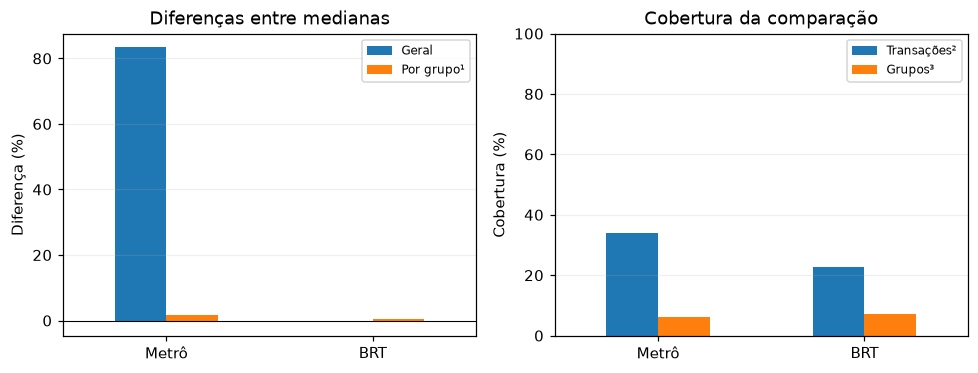

³ Grupos comparáveis / grupos avaliados com chaves completas e distância válida.

In [4]:
figura_comparacao(resumo)
plt.show()
display(Markdown("³ Grupos comparáveis / grupos avaliados com chaves completas e distância válida."))


**Interpretação.** Para o **Metrô**, a mediana de preços perto é **83,39% maior** que longe na comparação geral; a mediana das diferenças dentro dos **291 grupos comparáveis** é de **1,73%**. Esses grupos reúnem **107.385 transações**, ou **34,06% da amostra de preços**.

Para o **BRT**, as diferenças são de **−0,41%** na comparação geral e **0,35%** no resumo por grupo. Os **304 grupos** reúnem **71.832 transações**, ou **22,78% da amostra**. As medidas estão próximas de zero em termos descritivos; não foi realizado teste de significância.

As duas formas de comparação resumem estatísticas e conjuntos distintos. A discrepância no Metrô é compatível com diferenças de composição, mas não quantifica a contribuição de cada fator nem uma redução de efeito causal. Grupos excluídos podem ter características diferentes dos elegíveis.


### 5.6. A variabilidade dos valores do m² é diferente entre imóveis próximos e distantes dos pontos de acesso de Metrô, BRT, VLT e BRS?

*A finalizar na próxima entrega para as quatro modalidades.* As medianas da seção 5.5 não medem dispersão e não permitem responder a esta pergunta.


### 5.7. Existem diferenças na distribuição dos valores do m² entre imóveis próximos aos diferentes tipos de transporte?

*A finalizar na próxima entrega para Metrô, BRT, VLT e BRS.* A análise deverá comparar as distribuições e considerar transações próximas a mais de uma modalidade. As diferenças perto/longe da seção 5.5 não bastam para respondê-la.


### 5.8. Como os valores e sua variabilidade se comportam ao longo dos anos analisados?

*Mayara: integrar as agregações anuais, visualizações e interpretação da evolução dos preços e da dispersão, explicitando o tratamento da inflação e a comparabilidade dos períodos.*


## 6. Discussão e limitações

Os resultados parciais reforçam a necessidade de acompanhar as comparações agregadas com recortes comparáveis e sua cobertura. Mesmo dentro de bairro, ano e tipologia, permanecem diferenças de qualidade, área e localização. Os preços são nominais, a geocodificação tem limitações e a distância em linha reta não equivale ao percurso caminhável. A reconstrução histórica da rede depende das informações de operação disponíveis. Por isso, as associações observadas não identificam causalidade.

Na próxima entrega, a etapa de transporte completará médias, medianas, variabilidade e distribuições para **Metrô, BRT, VLT e BRS**, incluindo o critério de acesso ao BRS, a cobertura das comparações e as sobreposições entre modalidades. As verificações de concentração espacial e sensibilidade à distância também deverão ser documentadas.


## 7. Conclusão preliminar

A integração permitiu descrever a proximidade das transações ao Metrô, BRT e VLT e iniciar a comparação de preços para Metrô e BRT. No Metrô, a diferença geral é maior que o resumo dentro dos grupos comparáveis; no BRT, ambas as medidas estão próximas de zero. Como recomendação metodológica, a leitura desses resultados deve considerar a composição e a cobertura da amostra.

Esta entrega responde apenas parcialmente às perguntas de transporte. Sua conclusão depende das medidas previstas para as quatro modalidades e da integração das demais contribuições do grupo. Os achados atuais não sustentam atribuir diferenças de preço à implantação dos transportes nem recomendar investimentos específicos.


## Referências

### 1. Bases de dados principais

**RIO DE JANEIRO (Município). Secretaria Municipal de Fazenda.** ITBI — Transações imobiliárias no Município do Rio de Janeiro. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Bases utilizadas: *ITBI_TRANSACOES_PERIODO_2011_2018* e *ITBI_TRANSACOES_PERIODO_2019_2024*. Disponível em: https://fazenda.prefeitura.rio/itbi-valores-medios-por-m2-de-transacoes-imobiliarias-por-trecho-de-logradouro/. Acesso em: 22 out. 2026.

**RIO DE JANEIRO (Município). Data.Rio.** Estações BRT. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: https://www.data.rio/datasets/f753941f44a749d4987f1111aa6486b3_0/about. Acesso em: 17 set. 2026.

**RIO DE JANEIRO (Município). Data.Rio.** Estações Metrô. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: https://www.data.rio/datasets/PCRJ::esta%C3%A7%C3%B5es-metr%C3%B4/about. Acesso em: 17 set. 2026.

**RIO DE JANEIRO (Município). Data.Rio.** VLT. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: https://www.data.rio/datasets/29cc383d2d344e8387dda153ec0d545d_9/explore. Acesso em: 17 set. 2026.

**RIO DE JANEIRO (Município). Data.Rio.** BRS (Serviço Rápido de Ônibus). Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: https://www.data.rio/datasets/0b707ee14f3d4515ab513e7d078f0c1b_0/explore. Acesso em: 17 set. 2026.

### 2. Fontes auxiliares e complementares

#### 2.1. Geocodificação e tratamento dos dados

**INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE).** Cadastro Nacional de Endereços para Fins Estatísticos (CNEFE): Censo Demográfico 2022. Rio de Janeiro: IBGE, 2024. Disponível em: https://www.ibge.gov.br/estatisticas/sociais/habitacao/38734-cadastro-nacional-de-enderecos-para-fins-estatisticos.html. Acesso em: 22 out. 2026.

**PEREIRA, Rafael H. M.; HERSZENHUT, Daniel; ALMEIDA, Gabriel Garcia de.** geocodebr: geolocalização de endereços brasileiros. Instituto de Pesquisa Econômica Aplicada (Ipea), [s. d.]. Disponível em: https://ipea.github.io/geocodebr/. Acesso em: 22 out. 2026.

#### 2.2. Fontes históricas para complementação dos dados do VLT

**RIO DE JANEIRO (Município).** [Informações sobre a operação da Linha 1 do VLT e sua expansão até a Rodoviária]. Rio de Janeiro: Prefeitura, 2016. Disponível em: https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6268057. Acesso em: 21 out. 2026.

**RIO DE JANEIRO (Município).** [Informações sobre a operação da parada Gamboa do VLT]. Rio de Janeiro: Prefeitura, 2016. Disponível em: https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6548374. Acesso em: 21 out. 2026.

**RIO DE JANEIRO (Município).** [Informações sobre o início da operação das paradas Providência e Harmonia do VLT]. Rio de Janeiro: Prefeitura, 2017. Disponível em: https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=7056533. Acesso em: 21 out. 2026.

**RIO DE JANEIRO (Município).** Prefeitura inicia operação da Linha 3 do VLT que liga a Central do Brasil ao Aeroporto Santos Dumont. Rio de Janeiro: Prefeitura, 2019. Disponível em: https://en.prefeitura.rio/transportes/prefeitura-inicia-operacao-da-linha-3-do-vlt-que-liga-a-central-do-brasil-ao-aeroporto-santos-dumont/. Acesso em: 21 out. 2026.

**RIO DE JANEIRO (Município).** Prefeitura inaugura o Terminal Intermodal Gentileza. Rio de Janeiro: Prefeitura, 2024. Disponível em: https://prefeitura.rio/cidade/prefeitura-inaugura-o-terminal-intermodal-gentileza/. Acesso em: 21 out. 2026.


### Material complementar

Código de mobilidade: `02_mobilidade.ipynb`; integração espacial: `03_integracao_itbi.ipynb`. Repositório: <https://github.com/ana-alice17/mobilidade-imobiliario-rj>.
